In [9]:
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt

In [32]:
X = np.random.randn(1000)
one = np.ones((X.shape[0], 1))
Xbar = np.concatenate((one, X.reshape(-1, 1)), axis=1)
w_init = np.array([[2], [1]])
y = (4 + 3 * X + .5*np.random.randn(1000)).reshape(-1, 1)
model = LinearRegression()
model.fit(X.reshape(-1, 1), y.reshape(-1, 1))
w, b = model.coef_[0][0], model.intercept_[0]
print(w, b)

3.0246982060576317 4.019006070282698


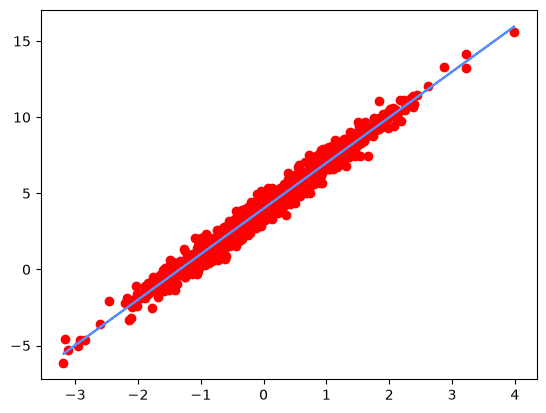

In [12]:
plt.plot(X, y, 'ro')
plt.plot(X, b + X * w, b)
plt.show()

In [33]:
def grad(w):
    N = Xbar.shape[0]
    return 1/N * Xbar.T.dot(Xbar.dot(w) - y)
def cost(w):
    N = Xbar.shape[0]
    return 0.5/N * np.linalg.norm(y - Xbar.dot(w))**2

In [37]:
def myGD(w_init, grad, eta):
    w = [w_init]
    for it in range(100):
        w_new = w[-1] - eta * grad(w[-1])
        if np.linalg.norm(grad(w_new))/len(w_new) < 1e-3:
            break
        w.append(w_new)
    return (w, it)


In [34]:
(w, it) = myGD(w_init, grad, 1)
print(w[-1].T)

[[3.98177961 3.00187898]]


In [47]:
#Momentnum
def GD_momentum(grad, theta_init, eta, gamma):
    theta = [theta_init]
    v_old = np.ones_like(theta_init)
    for it in range(100):
        v_new = gamma * v_old + eta * grad(theta[-1])
        theta_new = theta[-1] - v_new
        if np.linalg.norm(grad(theta_new))/np.array(theta_init).size < 1e-3:
            break
        theta.append(theta_new)
        v_old = v_new
    return theta[-1]

In [43]:
def GD_NAG(grad, theta_init, eta, gamma):
    theta = [theta_init]
    v = [np.zeros_like(theta_init)]
    for it in range(100):
        v_new = gamma * v[-1] + eta * grad(theta[-1] - gamma * v[-1])
        theta_new = theta[-1] - v_new
        if np.linalg.norm(grad(theta_new))/np.array(theta_init).size < 1e-3:
            break
        theta.append(theta_new)
        v .append(v_new)
    return theta[-1]

In [48]:
w1 = GD_momentum(grad, w_init, 1, 0.9)
w2 = GD_NAG(grad, w_init, 1, 0.9)
print(w1 - w2)

[[-0.04451612]
 [-0.02822047]]
